# EDA 03 · Transactions: subscription state at the cutoff

**Question.** How much of churn is explained by the *current* state of the subscription, and which state variables are worth keeping?

**Input.** Transactions cleaned with the rules of notebook 02 (`C.clean_transactions`) and collapsed to one state per customer (`C.subscription_state`): records are grouped per day before choosing "the last one", because file order is not time order.

| Variable | Definition |
|---|---|
| `state` | last transaction day: `auto-renew` payment, `manual` payment, `cancel`, `cancel + payment`, or `no txn` |
| `expiry_state` | latest expiry of that day vs the cutoff: `lapsed`, `february`, `march`, `april+`, `unknown` |
| `days_to_expire`, `days_since_last_txn` | days from the cutoff |
| `last_plan_days`, `last_list_price`, `last_paid`, `last_price_type`, `last_payment_method_id` | from the latest **payment** record |

**Population.** `fit` customers (notebook 00).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

EDA_DIR = next(p for p in (Path.cwd(), Path.cwd() / "eda") if (p / "_common.py").exists())
sys.path.insert(0, str(EDA_DIR))
import _common as C

pl.Config.set_tbl_rows(40); pl.Config.set_tbl_width_chars(160)
pd.options.display.float_format = "{:,.4f}".format
pd.set_option("display.max_colwidth", None)

users = C.load_fit_population()
BASE = users["is_churn"].mean()
txn = C.clean_transactions(users)
st = C.subscription_state(txn, users)
print(f"customers: {st.height:,} | base churn: {BASE:.2%}")

customers: 744,699 | base churn: 6.39%


## 1. Subscription state

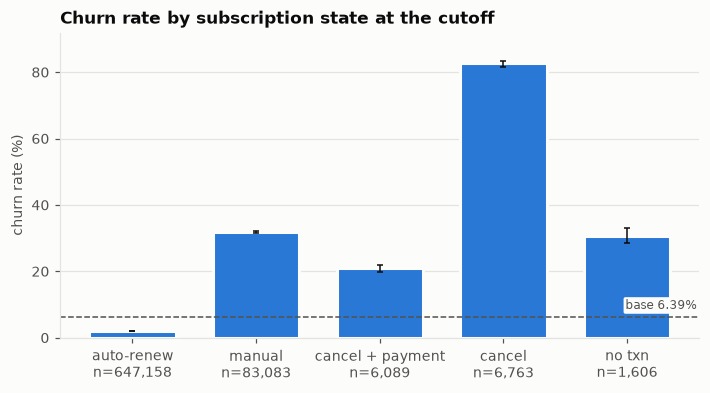

,state,n,churners,churn_rate,ci_low,ci_high,share,lift
0,auto-renew,647158,13867,0.0214,0.0211,0.0218,0.8690,0.3352
1,manual,83083,26384,0.3176,0.3144,0.3207,0.1116,4.9678
2,cancel + payment,6089,1272,0.2089,0.1989,0.2193,0.0082,3.2680
3,cancel,6763,5588,0.8263,0.8170,0.8351,0.0091,12.9257
4,no txn,1606,493,0.3070,0.2849,0.3300,0.0022,4.8022


In [2]:
state_tbl = C.churn_rate_by(st, "state", order=C.STATE_ORDER)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
C.plot_churn_rate(state_tbl, "state", ax=ax, base_rate=BASE, title="Churn rate by subscription state at the cutoff")
C.save_fig(fig, "03_state"); plt.show()
state_tbl

Four states cover almost the whole range of churn:

- **auto-renew** (87 % of customers) churns 2.1 %. Most churners still come from here because the group is so large, so it is where the other features have to work.
- **manual** payment (11 %) churns 32 %: the customer has to come back and pay by hand.
- **cancel** (0.9 %) churns 83 %.
- **cancel + payment** on the same day (0.8 %) churns 21 %, a state of its own (notebook 02).

## 2. State × expiry

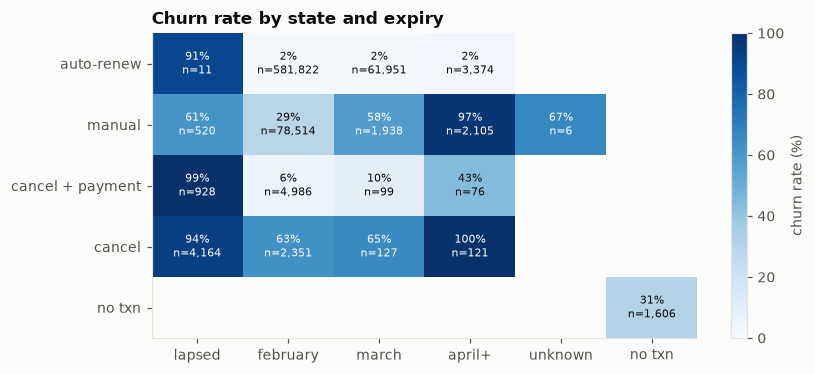

In [3]:
se = C.churn_rate_by(st, ["state", "expiry_state"], order=C.STATE_ORDER)
pivot_rate = se.pivot(index="state", columns="expiry_state", values="churn_rate").reindex(C.STATE_ORDER)
pivot_n = se.pivot(index="state", columns="expiry_state", values="n").reindex(C.STATE_ORDER)
cols = [c for c in C.EXPIRY_ORDER if c in pivot_rate.columns]
pivot_rate, pivot_n = pivot_rate[cols], pivot_n[cols]

fig, ax = plt.subplots(figsize=(8, 3.6))
im = ax.imshow(pivot_rate.to_numpy(dtype=float) * 100, cmap="Blues", vmin=0, vmax=100, aspect="auto")
for i in range(pivot_rate.shape[0]):
    for j in range(pivot_rate.shape[1]):
        r, n = pivot_rate.iat[i, j], pivot_n.iat[i, j]
        if pd.notna(r):
            ax.text(j, i, f"{r:.0%}\nn={int(n):,}", ha="center", va="center", fontsize=7.5,
                    color="white" if r > 0.55 else C.COLORS["text"])
ax.set_xticks(range(len(cols)), cols); ax.set_yticks(range(len(pivot_rate)), pivot_rate.index)
ax.grid(False); ax.set_title("Churn rate by state and expiry", loc="left")
fig.colorbar(im, ax=ax, label="churn rate (%)")
C.save_fig(fig, "03_state_x_expiry"); plt.show()

- Expiry splits the small states sharply. A **cancel + payment** day whose expiry is still in February churns 6 %, like an ordinary customer; the same day with a lapsed expiry churns 99 %. A **cancel** with a lapsed expiry churns 94 %, against 63 % if it still runs into February.
- For **auto-renew** customers expiry barely matters (2.1–2.4 % in February, March and later): the renewal is automatic.
- For **manual** customers, an expiry in March or later goes with *more* churn (58 % and 97 %). These are mostly long prepaid plans that do not renew by hand (section 3). The 97 % for `manual × april+` also says something about the label: a customer who prepaid until April or later and is in the February cohort is almost always labelled as churn.

State and expiry are complementary; neither replaces the other.

## 3. Plan length of the last payment

In [4]:
PLAN_ORDER = ["7 or less", "30-31", "32-200", "201+", "unknown"]
st = st.with_columns(plan_band=
    pl.when(pl.col("last_plan_days").is_null()).then(pl.lit("unknown"))
    .when(pl.col("last_plan_days") <= 7).then(pl.lit("7 or less"))
    .when(pl.col("last_plan_days") <= 31).then(pl.lit("30-31"))
    .when(pl.col("last_plan_days") <= 200).then(pl.lit("32-200"))
    .otherwise(pl.lit("201+")))
plan_tbl = C.churn_rate_by(st, "plan_band", order=PLAN_ORDER)
print(plan_tbl[["plan_band", "n", "share", "churn_rate"]])
ps = C.churn_rate_by(st.filter(pl.col("state").is_in(["auto-renew", "manual"])), ["plan_band", "state"], order=PLAN_ORDER)
ps[ps.n >= 200].pivot(index="plan_band", columns="state", values="churn_rate")

   plan_band       n  share  churn_rate
0  7 or less    2586 0.0035      0.7274
1      30-31  722885 0.9707      0.0506
2     32-200   11237 0.0151      0.4491
3       201+    6379 0.0086      0.5606
4    unknown    1612 0.0022      0.3083


state,auto-renew,manual
plan_band,,
201+,NaN,0.5598
30-31,0.0214,0.2642
32-200,NaN,0.4481
7 or less,NaN,0.5821


97 % of customers are on 30-day plans. Every non-monthly plan is risky: 7-day trials churn 73 %, plans of 32–200 days 45 % and plans over 200 days 56 %. Non-monthly plans are always manual, so the plan length mostly explains **which manual customers are risky**: manual monthly 26 %, manual long plan 45–56 %. A 4-level band is enough; the exact number of days adds little.

## 4. Price of the last payment

In [5]:
monthly = st.filter((pl.col("plan_band") == "30-31") & pl.col("state").is_in(["auto-renew", "manual"]))
pr = C.churn_rate_by(monthly.with_columns(pl.col("last_list_price").cast(pl.String)), ["last_list_price", "state"])
pr = pr[pr.n >= 1000]
pr.pivot(index="last_list_price", columns="state", values="churn_rate").join(
    pr.pivot(index="last_list_price", columns="state", values="n"), rsuffix="_n")

state,auto-renew,manual,auto-renew_n,manual_n
last_list_price,,,,
100,0.0214,NaN,"8,883.0000",NaN
129,0.0257,NaN,"28,420.0000",NaN
149,0.0237,0.2602,"282,316.0000","37,823.0000"
150,NaN,0.3025,NaN,"1,276.0000"
180,0.0387,0.2616,"37,227.0000","24,393.0000"
99,0.0165,NaN,"290,032.0000",NaN


In [6]:
pt = C.churn_rate_by(st.filter(pl.col("state").is_in(["auto-renew", "manual"])), ["last_price_type", "state"])
pt[pt.n >= 100][["last_price_type", "state", "n", "churn_rate"]]

,last_price_type,state,n,churn_rate
0,discounted,auto-renew,483,0.0083
1,free,auto-renew,1664,0.3419
2,free,manual,1887,0.6078
3,full,auto-renew,645011,0.0206
4,full,manual,81194,0.3108


- Among monthly **auto-renew** plans the list price orders churn: 1.7 % at 99, 2.1–2.6 % at 100–149, 3.9 % at 180. Among **manual** monthly plans there is no ordering (26–30 % at every price). Price is a signal inside the auto-renew group, the largest one.
- A **free** last payment (trial or free month) churns 34 % on auto-renew and 61 % on manual: the customer has not yet paid anything. Discounted payments are too rare at the cutoff to matter.

## 5. Payment method: signal or proxy for auto-renew?

In [7]:
pm = (st.filter(pl.col("last_payment_method_id").is_not_null())
        .group_by("last_payment_method_id")
        .agg(n=pl.len(), churn=pl.col("is_churn").mean(), auto_renew_share=(pl.col("state") == "auto-renew").mean())
        .sort("n", descending=True))
print(f"methods with >= 1,000 customers: {(pm['n'] >= 1000).sum()} of {pm.height}")
pm.head(20)

methods with >= 1,000 customers: 16 of 33


last_payment_method_id,n,churn,auto_renew_share
i8,u32,f64,f64
41,427121,0.026454,0.980465
40,56773,0.041939,0.984729
36,50332,0.115155,0.641143
39,49174,0.03451,0.975027
38,47271,0.30615,0.0
37,28933,0.020254,0.993502
34,22011,0.009722,0.998728
30,12122,0.120525,0.964362
29,11798,0.182319,0.420241


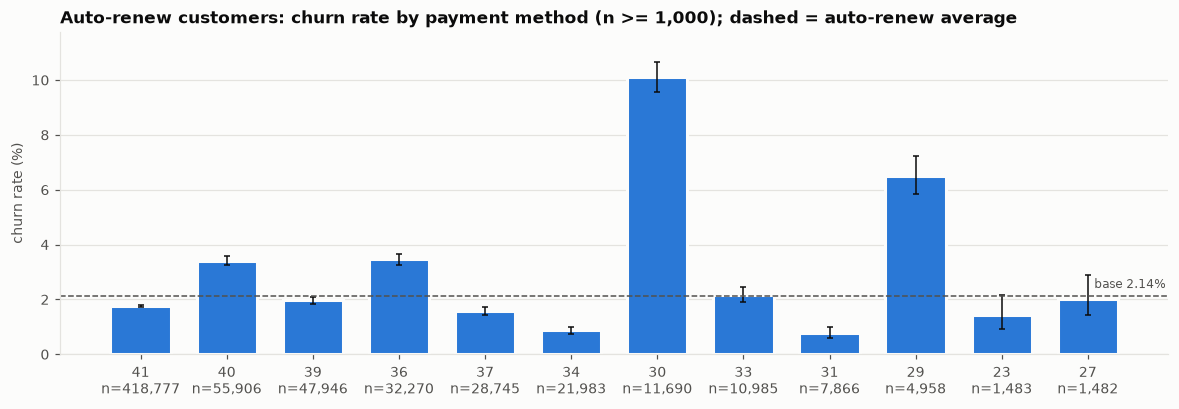

In [8]:
auto = st.filter(pl.col("state") == "auto-renew").with_columns(pm=pl.col("last_payment_method_id").cast(pl.String))
pm_auto = C.churn_rate_by(auto, "pm")
pm_auto = pm_auto[pm_auto.n >= 1000].sort_values("n", ascending=False).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(13, 3.8))
C.plot_churn_rate(pm_auto, "pm", ax=ax, base_rate=auto["is_churn"].mean(),
                  title="Auto-renew customers: churn rate by payment method (n >= 1,000); dashed = auto-renew average")
C.save_fig(fig, "03_payment_method_within_auto"); plt.show()

- Most methods are **pure**: always auto-renew (41, 40, 39, 37, 34, …) or never (38, 32, 35, 28, …). Across all customers the method therefore repeats what `state` already says.
- **Inside** the auto-renew state, methods still differ: most sit at 1–4 %, while methods 30 (10 %) and 29 (6 %) churn several times more. So the method carries some extra signal, which section 7 measures.

## 6. Days since the last transaction

In [9]:
DSL_ORDER = ["0-7", "8-31", "32-90", "91+"]
st = st.with_columns(dsl_band=pl.when(pl.col("days_since_last_txn") <= 7).then(pl.lit("0-7"))
    .when(pl.col("days_since_last_txn") <= 31).then(pl.lit("8-31"))
    .when(pl.col("days_since_last_txn") <= 90).then(pl.lit("32-90")).otherwise(pl.lit("91+")))
ds = C.churn_rate_by(st.filter(pl.col("state") != "no txn"), ["dsl_band", "state"], order=DSL_ORDER)
ds.pivot(index="dsl_band", columns="state", values="churn_rate").reindex(DSL_ORDER)[C.STATE_ORDER[:4]]

state,auto-renew,manual,cancel + payment,cancel
dsl_band,,,,
0-7,0.0193,0.3581,0.0505,0.7832
8-31,0.0223,0.2512,0.0572,0.8323
32-90,0.0934,0.4773,0.4474,0.8254
91+,0.7903,0.4580,0.9349,0.8933


Almost all auto-renew customers transacted in the last month (the monthly charge), so recency mostly re-describes the plan and the expiry. It helps in the rare cases where the last record is old (auto-renew with no transaction for 3+ months churns about 80 %), which the expiry state (`lapsed`) already flags.

## 7. What does each state variable add? (5-fold CV inside `fit`)

Logistic regression on one-hot bands, adding one block at a time; gradient boosting on the same inputs; and, for reference, gradient boosting on the **current w1 state features**, computed the way the w1 pipeline does today (last record by file order, raw zeros, expiry of that record).

In [10]:
pm_keep = set(pm.filter(pl.col("n") >= 1000)["last_payment_method_id"].to_list())
LIST_LEVELS = {"99", "100", "129", "149", "150", "180"}
st = st.with_columns(
    pm_group=pl.when(pl.col("last_payment_method_id").is_null()).then(pl.lit("none"))
    .when(pl.col("last_payment_method_id").is_in(list(pm_keep))).then(pl.col("last_payment_method_id").cast(pl.String))
    .otherwise(pl.lit("other")),
    price_level=pl.when(pl.col("last_list_price").cast(pl.String).is_in(list(LIST_LEVELS)))
    .then(pl.col("last_list_price").cast(pl.String)).otherwise(pl.lit("other")),
    price_type=pl.col("last_price_type").fill_null("none"),
)
X = st.select("state", "expiry_state", "plan_band", "price_level", "price_type", "pm_group", "dsl_band").to_pandas()
X["state_x_expiry"] = X["state"] + "|" + X["expiry_state"]
y = st["is_churn"].to_numpy()
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=C.SEED)

def logit(cat):
    return make_pipeline(ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), list(cat))]),
                         LogisticRegression(max_iter=3000))

def gbm(cols, cat_cols):
    pre = ColumnTransformer([("pass", "passthrough", [c for c in cols if c not in cat_cols]),
                             ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), list(cat_cols))])
    return make_pipeline(pre, HistGradientBoostingClassifier(max_iter=200, random_state=C.SEED))

def cv(model, data, cols):
    s = cross_validate(model, data[list(cols)], y, cv=CV, scoring=("roc_auc", "average_precision", "neg_log_loss"), n_jobs=5)
    return {"roc_auc": s["test_roc_auc"].mean(), "avg_precision": s["test_average_precision"].mean(),
            "log_loss": -s["test_neg_log_loss"].mean()}

steps = [
    ("state", ["state"]),
    ("+ expiry_state (x state)", ["state", "expiry_state", "state_x_expiry"]),
    ("+ plan_band", ["state", "expiry_state", "state_x_expiry", "plan_band"]),
    ("+ price level and type", ["state", "expiry_state", "state_x_expiry", "plan_band", "price_level", "price_type"]),
    ("+ payment method (grouped)", ["state", "expiry_state", "state_x_expiry", "plan_band", "price_level", "price_type", "pm_group"]),
    ("+ days since last txn", ["state", "expiry_state", "state_x_expiry", "plan_band", "price_level", "price_type", "pm_group", "dsl_band"]),
]
rows = {f"LR {name}": cv(logit(cols), X, cols) for name, cols in steps}
proposed = ["state", "expiry_state", "plan_band", "price_level", "price_type", "pm_group", "dsl_band"]
rows["GBM proposed (bands)"] = cv(gbm(proposed, proposed), X, proposed)

In [11]:
# Current w1 definition: deduplicated raw records, last by (transaction_date, file order), no cleaning.
raw = C.scan_transactions(users).collect(engine="streaming").unique(subset=["msno"] + C.TXN_COLS, keep="first", maintain_order=True)
w1 = (raw.sort("transaction_date", "_ord").group_by("msno").agg(
        last_is_auto_renew=pl.col("is_auto_renew").last(), last_is_cancel=pl.col("is_cancel").last(),
        last_plan_days=pl.col("payment_plan_days").last(), last_payment_method_id=pl.col("payment_method_id").last(),
        last_ed=pl.col("membership_expire_date").last(), last_td=pl.col("transaction_date").last()))
w1 = users.join(w1, on="msno", how="left").with_columns(
    days_to_expire=(C.to_date("last_ed") - pl.lit(C.CUTOFF)).dt.total_days(),
    days_since_last_transaction=(pl.lit(C.CUTOFF) - C.to_date("last_td")).dt.total_days())
W1_COLS = ["last_is_auto_renew", "last_is_cancel", "last_plan_days", "last_payment_method_id",
           "days_to_expire", "days_since_last_transaction"]
Xw = w1.select(W1_COLS).to_pandas().astype(float)
model = make_pipeline(HistGradientBoostingClassifier(max_iter=200, random_state=C.SEED,
                                                     categorical_features=[W1_COLS.index("last_payment_method_id")]))
Xw["last_payment_method_id"] = Xw["last_payment_method_id"].fillna(-1).astype(int) + 1
rows["GBM current w1 state features"] = cv(model, Xw, W1_COLS)
res = pd.DataFrame(rows).T
res

,roc_auc,avg_precision,log_loss
LR state,0.8142,0.3258,0.1694
LR + expiry_state (x state),0.8182,0.4002,0.1628
LR + plan_band,0.8217,0.4480,0.1610
LR + price level and type,0.8427,0.4730,0.1592
LR + payment method (grouped),0.8542,0.4879,0.1577
LR + days since last txn,0.8541,0.4955,0.1578
GBM proposed (bands),0.8569,0.5086,0.1560
GBM current w1 state features,0.8540,0.4868,0.1604



- `state` alone reaches ROC AUC 0.814. The rest of the state block lifts it to 0.854 and, more importantly for an imbalanced target, raises **average precision from 0.33 to 0.50**.
- Biggest increments: expiry (AP +0.074, through its interaction with the small states), price level and type (AUC +0.021) and payment method (AUC +0.012). Days since the last transaction adds almost nothing once expiry is known (AP +0.008, AUC flat).
- With the same model (gradient boosting), the proposed definitions beat the current w1 state features: AP 0.509 vs 0.487 and log-loss 0.156 vs 0.160, at a similar AUC. The gain comes from the cleaning in notebook 02 (day-level state, cancel + payment, valid expiry) and from price, which the current w1 set only has as long-run averages.


## 8. Conclusions


The current state of the subscription is the backbone of the problem: on its own (state + expiry + plan + price + method) it reaches ROC AUC 0.85–0.86 and AP about 0.50, against 0.70 for all the demographics of notebook 01.

- `state` (5 levels) replaces the pair `last_is_auto_renew` / `last_is_cancel` and fixes the same-day ambiguity.
- `expiry_state` matters only through the small states (cancel, cancel + payment, manual), so it should enter together with `state` (interaction for the linear model).
- Plan length works as 4 bands; price matters inside auto-renew; a free last payment is a strong risk flag.
- The payment method is mostly a copy of auto-renew, but keeps a small, real increment within the auto-renew group.


In [12]:
decisions = C.write_decisions("03", "Transactions: subscription state", [
    {"finding": "State of the last transaction day: auto-renew 2.1 %, manual 32 %, cancel 83 %, cancel + payment 21 %, no txn 31 %; AUC 0.814 alone",
     "decision": "New categorical `state` (5 levels), computed per day; replaces `last_is_auto_renew` and `last_is_cancel` (file order)",
     "kind": "new feature"},
    {"finding": "Expiry splits the small states (cancel + payment: 6 % if February, 99 % if lapsed); +0.074 AP",
     "decision": "New `expiry_state` (lapsed / february / march / april+ / unknown) plus `state x expiry_state` for the linear model; `days_to_expire` kept only as a numeric input for trees and w2",
     "kind": "new feature"},
    {"finding": "Manual payment with expiry in April or later churns 97 % (prepaid long plans in the February cohort)",
     "decision": "No special handling; covered by `state x expiry_state`. Mention as a label-definition quirk in the report",
     "kind": "no action"},
    {"finding": "Non-monthly plans churn 45-73 %; plan length matters only among manual customers",
     "decision": "`plan_band` (7 or less / 30-31 / 32-200 / 201+ / unknown) replaces `last_plan_days`",
     "kind": "transformation"},
    {"finding": "Inside auto-renew, list price orders churn (99: 1.7 %, 180: 3.9 %); free last payment churns 34-61 %",
     "decision": "New `last_list_price` level (99/100/129/149/150/180/other) and `last_price_type` (full / discounted / free)",
     "kind": "new feature"},
    {"finding": "Payment method is ~pure auto-renew or manual, but adds +0.012 AUC within auto-renew",
     "decision": "Keep `last_payment_method_id` from the last *payment* record, methods with < 1,000 fit customers grouped into `other` (16 + other)",
     "kind": "transformation"},
    {"finding": "Days since the last transaction adds ~0 AUC once expiry is known",
     "decision": "Keep only as a band (0-7 / 8-31 / 32-90 / 91+), low priority; re-check in notebook 08",
     "kind": "open"},
    {"finding": "Proposed state block beats current w1 state features with the same GBM (AP 0.509 vs 0.487, log-loss 0.156 vs 0.160)",
     "decision": "Adopt the proposed block in w1; w2 state channels should follow the same day-level rules",
     "kind": "transformation"},
    {"finding": "`expire_dayofweek` (current w1) has no rationale in any analysis",
     "decision": "Drop unless notebook 08 shows a gain",
     "kind": "open"},
])
decisions

,finding,decision,kind
0,"State of the last transaction day: auto-renew 2.1 %, manual 32 %, cancel 83 %, cancel + payment 21 %, no txn 31 %; AUC 0.814 alone","New categorical `state` (5 levels), computed per day; replaces `last_is_auto_renew` and `last_is_cancel` (file order)",new feature
1,"Expiry splits the small states (cancel + payment: 6 % if February, 99 % if lapsed); +0.074 AP",New `expiry_state` (lapsed / february / march / april+ / unknown) plus `state x expiry_state` for the linear model; `days_to_expire` kept only as a numeric input for trees and w2,new feature
2,Manual payment with expiry in April or later churns 97 % (prepaid long plans in the February cohort),No special handling; covered by `state x expiry_state`. Mention as a label-definition quirk in the report,no action
3,Non-monthly plans churn 45-73 %; plan length matters only among manual customers,`plan_band` (7 or less / 30-31 / 32-200 / 201+ / unknown) replaces `last_plan_days`,transformation
4,"Inside auto-renew, list price orders churn (99: 1.7 %, 180: 3.9 %); free last payment churns 34-61 %",New `last_list_price` level (99/100/129/149/150/180/other) and `last_price_type` (full / discounted / free),new feature
5,"Payment method is ~pure auto-renew or manual, but adds +0.012 AUC within auto-renew","Keep `last_payment_method_id` from the last *payment* record, methods with < 1,000 fit customers grouped into `other` (16 + other)",transformation
6,Days since the last transaction adds ~0 AUC once expiry is known,"Keep only as a band (0-7 / 8-31 / 32-90 / 91+), low priority; re-check in notebook 08",open
7,"Proposed state block beats current w1 state features with the same GBM (AP 0.509 vs 0.487, log-loss 0.156 vs 0.160)",Adopt the proposed block in w1; w2 state channels should follow the same day-level rules,transformation
8,`expire_dayofweek` (current w1) has no rationale in any analysis,Drop unless notebook 08 shows a gain,open


---
**Previous:** `02_transactions_quality.ipynb` · **Next:** `04_transactions_history.ipynb`